# CIFAR-10 Soft Neural Decision Tree

A self-contained PyTorch/Google Colab notebook. A compact CNN produces image features; **every routing node** and **every leaf** is its own small neural network. Soft path probabilities mix all leaf class distributions.

**CPU note:** the default run is deliberately a small smoke test. Set `PROFILE = "baseline"` or `"gpu"` only when you have time. Capacity sweeps are never run automatically.

In [15]:
# 1. Imports and configuration
import os, time, math, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Choose one: smoke (fast CPU check), baseline (overfitting experiment), gpu (larger run).
PROFILE = "baseline"
RUN_BASELINE = True
RUN_CAPACITY_SWEEP = False
RUN_MINIMIZATION_SWEEP = False
SEED = 42

PROFILES = {
    "smoke": dict(epochs=3, train_samples=4000, val_samples=1000, batch_size=128,
                  feature_size=32, hidden_size=8, depth=2, lr=2e-3),
    "baseline": dict(epochs=25, train_samples=20000, val_samples=5000, batch_size=128,
                     feature_size=64, hidden_size=16, depth=2, lr=1e-3),
    "gpu": dict(epochs=50, train_samples=None, val_samples=5000, batch_size=256,
                feature_size=128, hidden_size=32, depth=3, lr=1e-3),
}
CFG = PROFILES[PROFILE].copy()
NUM_CLASSES = 10
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print(f"Profile: {PROFILE} | baseline enabled: {RUN_BASELINE} | capacity sweep enabled: {RUN_CAPACITY_SWEEP}")

Profile: baseline | baseline enabled: True | capacity sweep enabled: False


In [16]:
# 2. Device detection and reproducibility
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

Using cpu


## Dataset and loaders

Validation comes only from CIFAR-10's original training data. The fixed split and deterministic subset make capacity comparisons fair. Normalization is the usual per-channel CIFAR-10 normalization.

In [17]:
# 3-4. CIFAR-10 download, fixed validation split, and loaders
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
DATA_ROOT = "./data"
full_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True, transform=transform)
test_dataset = datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=transform)

g = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(full_train), generator=g).tolist()
val_n = CFG["val_samples"]
val_indices = indices[:val_n]
train_indices = indices[val_n:]
if CFG["train_samples"] is not None:
    train_indices = train_indices[:CFG["train_samples"]]
train_dataset, val_dataset = Subset(full_train, train_indices), Subset(full_train, val_indices)
loader_args = dict(batch_size=CFG["batch_size"], num_workers=2, pin_memory=(device.type == "cuda"))
train_loader = DataLoader(train_dataset, shuffle=True, generator=torch.Generator().manual_seed(SEED), **loader_args)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_args)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_args)
print(f"train={len(train_dataset):,}, val={len(val_dataset):,}, test={len(test_dataset):,}")

train=20,000, val=5,000, test=10,000


## Neural tree architecture

At depth `d`, the tree has `2^d - 1` routing MLPs and `2^d` leaf MLPs. Larger depth therefore grows the number of separate neural networks exponentially. The CNN is shared across all nodes.

In [18]:
# 5-8. CNN feature extractor, routing-node MLPs, leaf MLPs, and soft tree
class FeatureExtractor(nn.Module):
    def __init__(self, feature_size):
        super().__init__()
        self.blocks = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(64, feature_size)
    def forward(self, x):
        return self.proj(self.blocks(x).flatten(1))

class RoutingNode(nn.Module):
    def __init__(self, feature_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(feature_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))
    def forward(self, features):
        return torch.sigmoid(self.net(features))  # P(right)

class LeafClassifier(nn.Module):
    def __init__(self, feature_size, hidden_size, num_classes=NUM_CLASSES):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(feature_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, num_classes))
    def forward(self, features):
        return F.softmax(self.net(features), dim=1)

class SoftNeuralTree(nn.Module):
    def __init__(self, feature_size=64, hidden_size=16, depth=2, num_classes=NUM_CLASSES):
        super().__init__()
        assert depth >= 1
        self.depth, self.num_classes = depth, num_classes
        self.feature_extractor = FeatureExtractor(feature_size)
        self.routing_nodes = nn.ModuleList([RoutingNode(feature_size, hidden_size) for _ in range(2**depth - 1)])
        self.leaves = nn.ModuleList([LeafClassifier(feature_size, hidden_size, num_classes) for _ in range(2**depth)])

    def forward(self, x, return_details=False):
        f = self.feature_extractor(x)
        # Start at root. At each level, retain probabilities for all nodes at that level.
        path_prob = torch.ones(x.size(0), 1, device=x.device)
        all_routes = []
        offset = 0
        for level in range(self.depth):
            n = 2**level
            route_right = torch.cat([self.routing_nodes[offset + j](f) for j in range(n)], dim=1)
            all_routes.append(route_right)
            next_prob = torch.empty(x.size(0), n * 2, device=x.device)
            next_prob[:, 0::2] = path_prob * (1 - route_right)
            next_prob[:, 1::2] = path_prob * route_right
            path_prob, offset = next_prob, offset + n
        leaf_probs = torch.stack([leaf(f) for leaf in self.leaves], dim=1)  # B, L, C
        prediction = (path_prob.unsqueeze(-1) * leaf_probs).sum(dim=1)
        if return_details:
            return prediction, {"features": f, "path_prob": path_prob, "leaf_probs": leaf_probs, "routes": all_routes}
        return prediction


In [19]:
# 9-10. Model sanity checks and parameter count
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model = SoftNeuralTree(CFG["feature_size"], CFG["hidden_size"], CFG["depth"]).to(device)
x_check = torch.randn(4, 3, 32, 32, device=device)
with torch.no_grad():
    y_check, details = model(x_check, return_details=True)
assert y_check.shape == (4, NUM_CLASSES)
assert details["path_prob"].shape == (4, 2**CFG["depth"])
assert torch.allclose(details["path_prob"].sum(1), torch.ones(4, device=device), atol=1e-5)
assert torch.allclose(y_check.sum(1), torch.ones(4, device=device), atol=1e-5)
print(f"Sanity checks passed. Parameters: {count_parameters(model):,}")

Sanity checks passed. Parameters: 68,491


In [20]:
# 11. Training, validation, checkpointing, and evaluation
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = total_correct = total_n = 0
    for batch_i, (images, targets) in enumerate(loader, 1):
        images, targets = images.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            probs = model(images)
            loss = F.nll_loss(torch.log(probs.clamp_min(1e-8)), targets)
            if training:
                loss.backward(); optimizer.step()
        total_loss += loss.item() * targets.size(0)
        total_correct += (probs.argmax(1) == targets).sum().item()
        total_n += targets.size(0)
        if training and (batch_i == 1 or batch_i % 25 == 0):
            print(f"  batch {batch_i:>3}/{len(loader)}", flush=True)
    return {"loss": total_loss / total_n, "acc": total_correct / total_n}

def fit(config, train_loader=train_loader, val_loader=val_loader, label="baseline"):
    seed_everything()
    model = SoftNeuralTree(config["feature_size"], config["hidden_size"], config["depth"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["lr"])
    best_state, best_val_acc, history = None, -1.0, []
    start = time.time()
    for epoch in range(1, config["epochs"] + 1):
        print(f"{label}: epoch {epoch}/{config['epochs']}", flush=True)
        train_m = run_epoch(model, train_loader, optimizer)
        val_m = run_epoch(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train_m["loss"], "train_acc": train_m["acc"], **{f"val_{k}": v for k,v in val_m.items()}})
        if val_m["acc"] > best_val_acc:
            best_val_acc, best_state = val_m["acc"], copy.deepcopy(model.state_dict())
        elapsed = time.time() - start
        print(f"  train acc {train_m['acc']:.3f}, val acc {val_m['acc']:.3f}, val loss {val_m['loss']:.3f} | {elapsed/epoch:.1f}s/epoch", flush=True)
    model.load_state_dict(best_state)
    Path("checkpoints").mkdir(exist_ok=True)
    torch.save({"config": config, "state_dict": model.state_dict()}, f"checkpoints/{label}_best.pt")
    return model, pd.DataFrame(history)

def evaluate(model, loader):
    return run_epoch(model, loader)


In [21]:
# 12. Baseline training experiment
if RUN_BASELINE:
    model, history = fit(CFG)
    test_metrics = evaluate(model, test_loader)
    print(f"Best-model test accuracy: {test_metrics['acc']:.3f}; test loss: {test_metrics['loss']:.3f}")
else:
    print("Baseline skipped. Set RUN_BASELINE = True to train.")

baseline: epoch 1/25
  batch   1/157
  batch  25/157
  batch  50/157
  batch  75/157
  batch 100/157
  batch 125/157
  batch 150/157
  train acc 0.225, val acc 0.284, val loss 1.842 | 51.7s/epoch
baseline: epoch 2/25
  batch   1/157
  batch  25/157
  batch  50/157
  batch  75/157
  batch 100/157
  batch 125/157
  batch 150/157
  train acc 0.316, val acc 0.342, val loss 1.718 | 50.4s/epoch
baseline: epoch 3/25
  batch   1/157
  batch  25/157
  batch  50/157
  batch  75/157
  batch 100/157
  batch 125/157
  batch 150/157
  train acc 0.367, val acc 0.381, val loss 1.624 | 50.3s/epoch
baseline: epoch 4/25
  batch   1/157
  batch  25/157
  batch  50/157
  batch  75/157
  batch 100/157
  batch 125/157
  batch 150/157
  train acc 0.395, val acc 0.404, val loss 1.575 | 49.8s/epoch
baseline: epoch 5/25
  batch   1/157
  batch  25/157
  batch  50/157
  batch  75/157
  batch 100/157
  batch 125/157
  batch 150/157
  train acc 0.414, val acc 0.431, val loss 1.542 | 49.9s/epoch
baseline: epoch 6/25

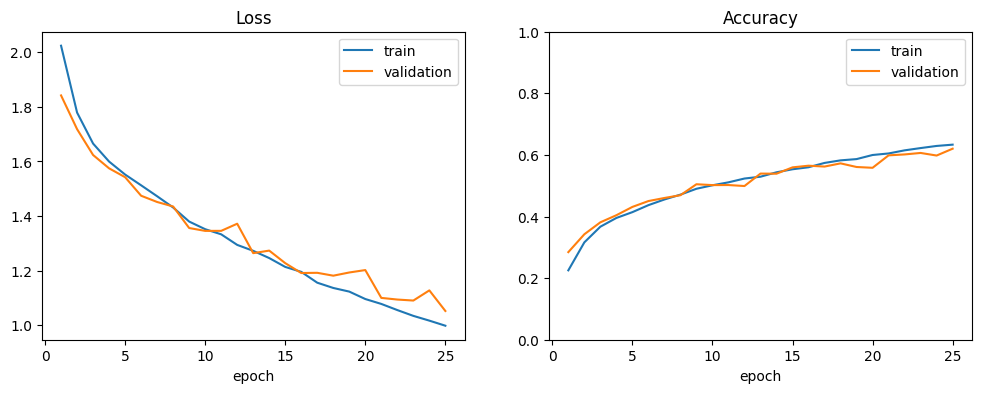

Overfitting evidence: training loss continues down / training accuracy rises while validation loss rises or validation accuracy stalls/falls.


In [22]:
# 13. Training and validation curves (run after baseline)
if RUN_BASELINE:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.epoch, history.train_loss, label="train"); ax[0].plot(history.epoch, history.val_loss, label="validation")
    ax[0].set(title="Loss", xlabel="epoch"); ax[0].legend()
    ax[1].plot(history.epoch, history.train_acc, label="train"); ax[1].plot(history.epoch, history.val_acc, label="validation")
    ax[1].set(title="Accuracy", xlabel="epoch", ylim=(0, 1)); ax[1].legend(); plt.show()
    print("Overfitting evidence: training loss continues down / training accuracy rises while validation loss rises or validation accuracy stalls/falls.")

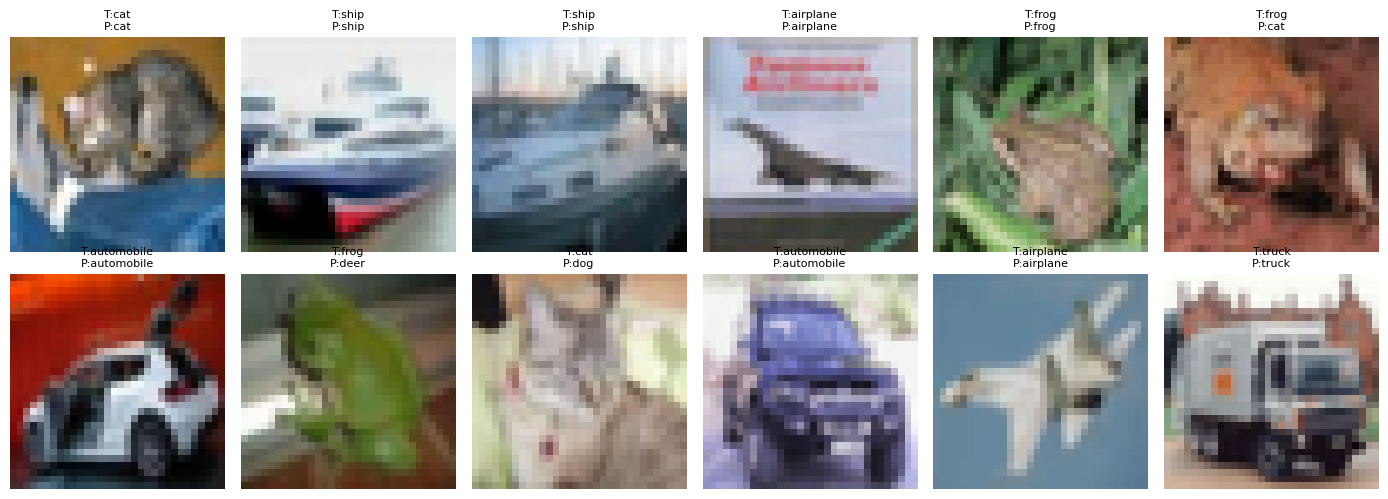

In [23]:
# 14. Example predictions and test evaluation (run after baseline)
if RUN_BASELINE:
    images, targets = next(iter(test_loader)); images = images.to(device)
    with torch.no_grad(): pred = model(images).argmax(1).cpu()
    fig, axes = plt.subplots(2, 6, figsize=(14, 5))
    for ax, image, truth, guess in zip(axes.flat, images[:12].cpu(), targets[:12], pred[:12]):
        img = image.permute(1,2,0) * torch.tensor(STD) + torch.tensor(MEAN)
        ax.imshow(img.clamp(0,1)); ax.set_title(f"T:{CLASS_NAMES[truth]}\nP:{CLASS_NAMES[guess]}", fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()

## Capacity / double-descent experiment

This is optional and does not claim double descent. The CPU version uses a fixed, deterministic small subset and only three capacities. It is a quick probe, not strong scientific evidence. A double-descent-like result needs validation error to rise near the point where training error becomes near zero, then fall again at higher capacity. A simple upward trend or a single U-shape is **not** double descent.

cap_f16_h4_d1: epoch 1/8
  batch   1/24
  train acc 0.111, val acc 0.140, val loss 2.283 | 8.1s/epoch
cap_f16_h4_d1: epoch 2/8
  batch   1/24
  train acc 0.144, val acc 0.141, val loss 2.258 | 7.8s/epoch
cap_f16_h4_d1: epoch 3/8
  batch   1/24
  train acc 0.155, val acc 0.160, val loss 2.185 | 8.1s/epoch
cap_f16_h4_d1: epoch 4/8
  batch   1/24
  train acc 0.178, val acc 0.195, val loss 2.129 | 7.9s/epoch
cap_f16_h4_d1: epoch 5/8
  batch   1/24
  train acc 0.201, val acc 0.181, val loss 2.135 | 8.1s/epoch
cap_f16_h4_d1: epoch 6/8
  batch   1/24
  train acc 0.203, val acc 0.197, val loss 2.059 | 7.9s/epoch
cap_f16_h4_d1: epoch 7/8
  batch   1/24
  train acc 0.213, val acc 0.202, val loss 2.069 | 8.0s/epoch
cap_f16_h4_d1: epoch 8/8
  batch   1/24
  train acc 0.224, val acc 0.209, val loss 2.015 | 8.1s/epoch
cap_f32_h8_d2: epoch 1/8
  batch   1/24
  train acc 0.122, val acc 0.184, val loss 2.209 | 7.3s/epoch
cap_f32_h8_d2: epoch 2/8
  batch   1/24
  train acc 0.199, val acc 0.217, val loss

,feature_size,hidden_size,depth,parameters,train_accuracy,validation_accuracy,validation_error
0,16,4,1,57669,0.224,0.209,0.791
1,32,8,2,60635,0.271,0.269,0.731
2,64,16,2,68491,0.304,0.289,0.711


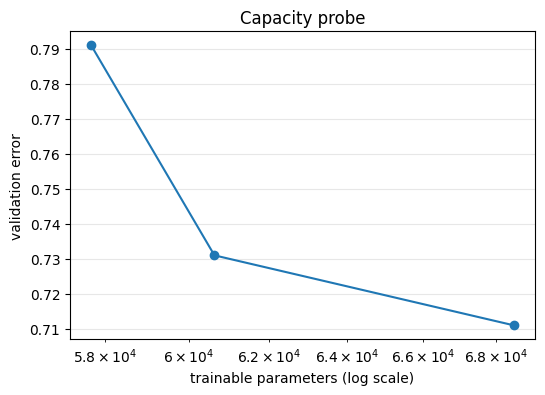

No tested model reached 99% train accuracy; interpolation threshold was not observed.


In [24]:
# 15. Optional capacity sweep: parameter count vs validation error
# CPU: 3 models x 8 epochs on exactly the same subset. GPU: expand this list / epochs if desired.
CPU_CAPACITIES = [(16, 4, 1), (32, 8, 2), (64, 16, 2)]  # feature_size, hidden_size, depth
RUN_CAPACITY_SWEEP = True;
def make_fixed_subset_loaders(train_n=3000, val_n=1000):
    fixed_train = Subset(full_train, train_indices[:min(train_n, len(train_indices))])
    fixed_val = Subset(full_train, val_indices[:min(val_n, len(val_indices))])
    args = dict(batch_size=CFG["batch_size"], num_workers=2, pin_memory=(device.type == "cuda"))
    return DataLoader(fixed_train, shuffle=True, generator=torch.Generator().manual_seed(SEED), **args), DataLoader(fixed_val, shuffle=False, **args)

def capacity_sweep(capacities=CPU_CAPACITIES, epochs=8):
    fixed_train, fixed_val = make_fixed_subset_loaders()
    rows = []
    for feature_size, hidden_size, depth in capacities:
        config = dict(CFG, feature_size=feature_size, hidden_size=hidden_size, depth=depth, epochs=epochs)
        candidate, h = fit(config, fixed_train, fixed_val, f"cap_f{feature_size}_h{hidden_size}_d{depth}")
        final = h.iloc[-1]
        rows.append(dict(feature_size=feature_size, hidden_size=hidden_size, depth=depth, parameters=count_parameters(candidate),
                         train_accuracy=final.train_acc, validation_accuracy=final.val_acc, validation_error=1-final.val_acc))
    results = pd.DataFrame(rows).sort_values("parameters").reset_index(drop=True)
    results.to_csv("capacity_results.csv", index=False)
    display(results.style.format({"train_accuracy": "{:.3f}", "validation_accuracy": "{:.3f}", "validation_error": "{:.3f}"}))
    plt.figure(figsize=(6,4)); plt.plot(results.parameters, results.validation_error, "o-")
    plt.xscale("log"); plt.xlabel("trainable parameters (log scale)"); plt.ylabel("validation error"); plt.title("Capacity probe"); plt.grid(alpha=.3); plt.show()
    near_zero = results[results.train_accuracy >= .99]
    if len(near_zero): print(f"Approximate interpolation threshold: {near_zero.iloc[0].parameters:,} parameters (first train accuracy >= 99%).")
    else: print("No tested model reached 99% train accuracy; interpolation threshold was not observed.")
    return results

if RUN_CAPACITY_SWEEP:
    capacity_results = capacity_sweep()
else:
    print("Sweep skipped. Change RUN_CAPACITY_SWEEP to True only when ready.")

True class: cat  predicted: cat
Leaf reach probabilities: [0.083 0.64  0.073 0.205]
Leaf class predictions: ['frog', 'cat', 'cat', 'dog']


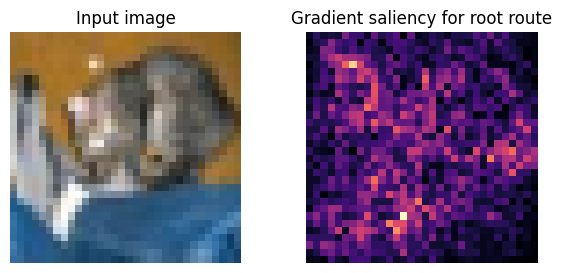

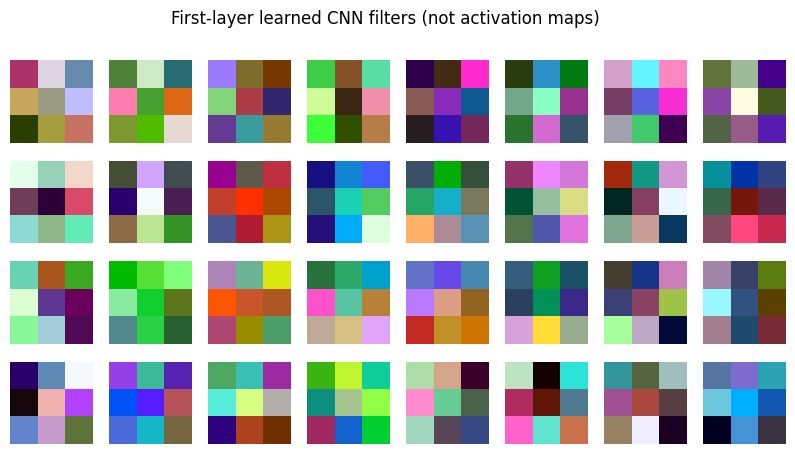

The CNN has spatial receptive fields; routing MLPs consume the CNN feature vector. Saliency maps image regions that change a routing score.


In [25]:
# 16. Routing, leaves, CNN filters, and gradient saliency (run after baseline)
if RUN_BASELINE:
    image, target = test_dataset[0]
    x = image.unsqueeze(0).to(device).requires_grad_(True)
    model.eval(); probs, d = model(x, return_details=True)
    print("True class:", CLASS_NAMES[target], " predicted:", CLASS_NAMES[probs.argmax(1).item()])
    print("Leaf reach probabilities:", d["path_prob"].squeeze().detach().cpu().numpy().round(3))
    print("Leaf class predictions:", [CLASS_NAMES[p.argmax().item()] for p in d["leaf_probs"].squeeze(0)])
    # This is routing analysis, not a spatial receptive field of the MLP.
    route_score = d["routes"][0][0, 0]
    model.zero_grad(); route_score.backward()
    saliency = x.grad.abs().max(dim=1).values[0].detach().cpu()
    fig, ax = plt.subplots(1, 2, figsize=(7,3))
    display_img = image.permute(1,2,0) * torch.tensor(STD) + torch.tensor(MEAN)
    ax[0].imshow(display_img.clamp(0,1)); ax[0].set_title("Input image"); ax[0].axis("off")
    ax[1].imshow(saliency, cmap="magma"); ax[1].set_title("Gradient saliency for root route"); ax[1].axis("off"); plt.show()
    filters = model.feature_extractor.blocks[0].weight.detach().cpu()
    fig, axes = plt.subplots(4, 8, figsize=(10,5))
    for ax, filt in zip(axes.flat, filters):
        v = filt.permute(1,2,0); v = (v-v.min())/(v.max()-v.min()+1e-8)
        ax.imshow(v); ax.axis("off")
    fig.suptitle("First-layer learned CNN filters (not activation maps)"); plt.show()
    print("The CNN has spatial receptive fields; routing MLPs consume the CNN feature vector. Saliency maps image regions that change a routing score.")

In [26]:
# 17. Optional network-size minimization
# Compare measured validation accuracy against size; never claim a configuration preserves accuracy until results show it.
SMALL_CONFIGS = [(16,4,1), (24,6,1), (32,8,2), (48,12,2)]
if RUN_MINIMIZATION_SWEEP:
    size_results = capacity_sweep(SMALL_CONFIGS, epochs=8)
    plt.figure(figsize=(6,4)); plt.scatter(size_results.parameters, size_results.validation_accuracy)
    plt.xscale("log"); plt.xlabel("trainable parameters"); plt.ylabel("validation accuracy"); plt.title("Accuracy versus network size"); plt.grid(alpha=.3); plt.show()
    print("Choose the smallest model within a report-defined accuracy tolerance of the best measured result.")

## 18. Report-ready conclusions

- Report the exact profile, split seed, epochs, and parameter counts; use the displayed metrics, never invented values.
- If train accuracy rises toward 100% while validation accuracy plateaus or declines, that is ordinary overfitting.
- If validation error does not first worsen and then improve after near-zero train error, write: *“This limited capacity sweep did not demonstrate double descent; it only measures the observed capacity–generalization trade-off.”*
- Increasing feature/hidden size increases parameters inside each node; increasing depth also doubles the leaves and nearly doubles the routing networks, raising training and inference cost.

In [27]:
# 20–30 minute overfitting experiment: aim for near-100% TRAIN accuracy.
# Uses the existing full_train, train_indices, val_indices, device, run_epoch,
# count_parameters, CLASS_NAMES, and test_loader variables.

OVERFIT_CONFIG = dict(
    epochs=200,
    feature_size=128,
    hidden_size=64,
    depth=2,
    lr=2e-3,
)

# Replace the CNN feature extractor with one that preserves spatial information.
class FeatureExtractor(nn.Module):
    def __init__(self, feature_size):
        super().__init__()
        self.blocks = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
        )
        self.proj = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, feature_size),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.proj(self.blocks(x))

# Fixed, deterministic 1,000-image train/validation subsets.
overfit_train_dataset = Subset(full_train, train_indices[:1000])
overfit_val_dataset = Subset(full_train, val_indices[:1000])

overfit_loader_args = dict(
    batch_size=128,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
)

overfit_train_loader = DataLoader(
    overfit_train_dataset,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    **overfit_loader_args,
)
overfit_val_loader = DataLoader(
    overfit_val_dataset,
    shuffle=False,
    **overfit_loader_args,
)

seed_everything(SEED)
overfit_model = SoftNeuralTree(
    feature_size=OVERFIT_CONFIG["feature_size"],
    hidden_size=OVERFIT_CONFIG["hidden_size"],
    depth=OVERFIT_CONFIG["depth"],
).to(device)

overfit_optimizer = torch.optim.Adam(
    overfit_model.parameters(),
    lr=OVERFIT_CONFIG["lr"],
)

overfit_history = []
best_val_accuracy = -1.0
best_state = None
start_time = time.time()

print(f"Overfit model parameters: {count_parameters(overfit_model):,}")
print("Target: near-100% training accuracy. Validation accuracy is expected to be lower.")

for epoch in range(1, OVERFIT_CONFIG["epochs"] + 1):
    print(f"\nOverfit run: epoch {epoch}/{OVERFIT_CONFIG['epochs']}", flush=True)

    train_metrics = run_epoch(
        overfit_model,
        overfit_train_loader,
        optimizer=overfit_optimizer,
    )
    val_metrics = run_epoch(overfit_model, overfit_val_loader)

    overfit_history.append({
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_acc": train_metrics["acc"],
        "val_loss": val_metrics["loss"],
        "val_acc": val_metrics["acc"],
    })

    if val_metrics["acc"] > best_val_accuracy:
        best_val_accuracy = val_metrics["acc"]
        best_state = copy.deepcopy(overfit_model.state_dict())

    elapsed_minutes = (time.time() - start_time) / 60
    print(
        f"train acc: {train_metrics['acc']:.3f} | "
        f"val acc: {val_metrics['acc']:.3f} | "
        f"elapsed: {elapsed_minutes:.1f} min",
        flush=True,
    )

    if train_metrics["acc"] >= 0.995:
        print("\nReached 99.5% training accuracy — stopping early.")
        break

# Save the best validation checkpoint and show the overfitting curves.
Path("checkpoints").mkdir(exist_ok=True)
overfit_model.load_state_dict(best_state)
torch.save(
    {
        "config": OVERFIT_CONFIG,
        "state_dict": overfit_model.state_dict(),
    },
    "checkpoints/overfit_30min_best.pt",
)

overfit_history = pd.DataFrame(overfit_history)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(overfit_history["epoch"], overfit_history["train_loss"], label="train")
ax[0].plot(overfit_history["epoch"], overfit_history["val_loss"], label="validation")
ax[0].set_title("Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(overfit_history["epoch"], overfit_history["train_acc"], label="train")
ax[1].plot(overfit_history["epoch"], overfit_history["val_acc"], label="validation")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylim(0, 1)
ax[1].legend()

plt.show()

test_metrics = run_epoch(overfit_model, test_loader)
print(f"Best-validation checkpoint test accuracy: {test_metrics['acc']:.3f}")
display(overfit_history.tail())

Overfit model parameters: 641,323
Target: near-100% training accuracy. Validation accuracy is expected to be lower.

Overfit run: epoch 1/200
  batch   1/8
train acc: 0.112 | val acc: 0.196 | elapsed: 0.1 min

Overfit run: epoch 2/200
  batch   1/8
train acc: 0.211 | val acc: 0.228 | elapsed: 0.1 min

Overfit run: epoch 3/200
  batch   1/8
train acc: 0.261 | val acc: 0.314 | elapsed: 0.2 min

Overfit run: epoch 4/200
  batch   1/8
train acc: 0.341 | val acc: 0.270 | elapsed: 0.3 min

Overfit run: epoch 5/200
  batch   1/8


KeyboardInterrupt: 

/tmp/ipykernel_529/1039128937.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


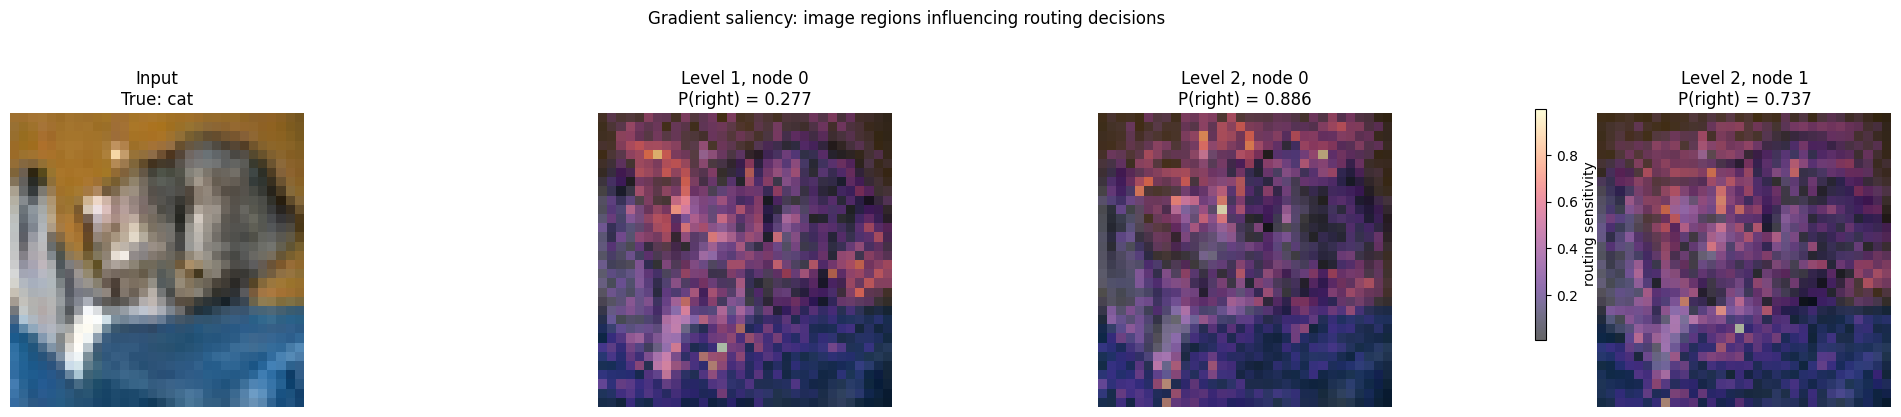

In [28]:
# Effective receptive-field visualization for routing nodes.
# Shows which image pixels most influence P(route right) at each selected node.

model.eval()

sample_index = 0
image, true_label = test_dataset[sample_index]

# Visualize root plus both nodes at level 2 when the tree has depth >= 2.
node_specs = [(0, 0)]  # (tree level, node index at that level)
if model.depth >= 2:
    node_specs += [(1, 0), (1, 1)]

def unnormalize(image_tensor):
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (image_tensor.cpu() * std + mean).clamp(0, 1)

display_image = unnormalize(image).permute(1, 2, 0)

fig, axes = plt.subplots(1, len(node_specs) + 1, figsize=(5 * (len(node_specs) + 1), 4))

axes[0].imshow(display_image)
axes[0].set_title(f"Input\nTrue: {CLASS_NAMES[true_label]}")
axes[0].axis("off")

for ax, (level, node_index) in zip(axes[1:], node_specs):
    # Make a fresh differentiable copy for each routing-node gradient.
    x = image.unsqueeze(0).to(device).detach().clone().requires_grad_(True)

    model.zero_grad(set_to_none=True)
    _, details = model(x, return_details=True)

    # Routing probability for this node: probability of taking its right branch.
    route_right = details["routes"][level][0, node_index]
    route_right.backward()

    # Maximum absolute gradient across RGB channels = pixel importance.
    saliency = x.grad.detach().abs().amax(dim=1)[0].cpu()
    saliency = saliency / (saliency.max() + 1e-8)

    ax.imshow(display_image)
    heatmap = ax.imshow(saliency, cmap="magma", alpha=0.60)
    ax.set_title(
        f"Level {level + 1}, node {node_index}\n"
        f"P(right) = {route_right.item():.3f}"
    )
    ax.axis("off")

fig.colorbar(heatmap, ax=axes[1:].tolist(), shrink=0.75, label="routing sensitivity")
plt.suptitle("Gradient saliency: image regions influencing routing decisions", y=1.03)
plt.tight_layout()
plt.show()